# 15 — Serie histórica 2007-2023 y comparación con el CEJA
El capítulo 9 publica el movimiento de causas **año por año desde 2007** para capitales (9.1.4), provincias (9.1.8) y el total
nacional (9.1.12), con todas las materias juntas. Es la única serie larga del Anuario. Este notebook la verifica, calcula los
indicadores del CEJA para cada año, los compara con los valores que el CEJA publicó para Bolivia (2018-2022) y aporta el
año 2023, que el CEJA no tenía. También mira cómo se movieron las materias desde 2020 con los cuadros de resueltas por año
(9.1.2, 9.1.6, 9.1.10).

Solo **agrega** archivos nuevos en `data/curated/eda/`.

In [1]:
%run -i modulos/comun.ipynb
%run -i modulos/flujo.ipynb
import numpy as np
import matplotlib.pyplot as plt

OUT_EDA = CURATED / "eda"
OUT_EDA.mkdir(parents=True, exist_ok=True)

serie = pd.read_parquet(PROCESSED / "causas_serie_historica.parquet")
gestion = pd.read_parquet(PROCESSED / "causas_por_gestion.parquet")
discrepancias = pd.read_csv(PROCESSED / "auditoria" / "discrepancias.csv")
assert serie.groupby("ambito").size().to_dict() == {"capital": 17, "nacional": 17, "provincia": 17}
assert sorted(serie["gestion"].unique()) == list(range(2007, 2024))
print(len(serie), "filas: 3 ámbitos × 17 años (2007-2023)")

51 filas: 3 ámbitos × 17 años (2007-2023)


## Control 1: las identidades de cada año
Igual que en el notebook 14: toda fila que no cierre tiene que estar ya registrada como discrepancia de la fuente.

In [2]:
s = serie.copy()
s["d_entrada"] = s["pendientes_inicio"] + s["ingresadas"] - s["atendidas"]
s["d_salida"] = s["atendidas"] - s["resueltas"] - s["pendientes_fin"]
rotas = s[(s["d_entrada"] != 0) | (s["d_salida"] != 0)]
registro = discrepancias[discrepancias["cuadro_origen"].astype(str).isin(["9.1.4", "9.1.8", "9.1.12"])].copy()
registro["entidad"] = registro["entidad"].astype(str)
for _, f in rotas.iterrows():
    assert len(registro[(registro["cuadro_origen"] == f["cuadro_origen"]) & (registro["entidad"] == str(f["gestion"]))]) > 0, \
        "identidad rota y no registrada: " + str(f["cuadro_origen"]) + " " + str(f["gestion"])
print(len(s) - len(rotas), "de", len(s), "filas cierran sus identidades;", len(rotas), "no (ya registradas):")
rotas[["ambito", "gestion", "d_entrada", "d_salida"]].sort_values(["gestion", "ambito"]).reset_index(drop=True)

42 de 51 filas cierran sus identidades; 9 no (ya registradas):


,ambito,gestion,d_entrada,d_salida
0,nacional,2018,0,-28
1,provincia,2018,0,-28
2,capital,2019,-76,0
3,nacional,2019,-70,5
4,provincia,2019,6,5
5,capital,2022,-2,1
6,nacional,2022,-2,1
7,capital,2023,1,0
8,nacional,2023,1,0


## Control 2: capital + provincia = nacional, año por año

In [3]:
cols = COLUMNAS_FLUJO
pv = serie.pivot_table(index="gestion", columns="ambito", values=cols, aggfunc="sum")
for c in cols:
    dif = pv[(c, "capital")] + pv[(c, "provincia")] - pv[(c, "nacional")]
    assert (dif == 0).all(), c + ": capital + provincia no reproduce el nacional"
print("17 años × 5 columnas: capital + provincia = nacional (0 diferencias)")

17 años × 5 columnas: capital + provincia = nacional (0 diferencias)


## Control 3, un hallazgo sobre la fuente: el stock de apertura no es el cierre del año anterior
En un registro que se conserva, `pendientes_inicio` de un año tendría que ser igual a `pendientes_fin` del anterior. No lo es.
No se corrige ni se interpola: se mide y queda como **límite** del análisis. Significa que el stock publicado no se puede
reconstruir sumando flujos año tras año, y que las comparaciones de stock entre años hay que leerlas con esa reserva.

In [4]:
enlace = []
for ambito in ["nacional", "capital", "provincia"]:
    t = serie[serie["ambito"] == ambito].sort_values("gestion").set_index("gestion")
    for anio in range(2008, 2024):
        cierre_anterior = int(t.loc[anio - 1, "pendientes_fin"])
        apertura = int(t.loc[anio, "pendientes_inicio"])
        enlace.append({"ambito": ambito, "gestion": anio, "cierre_anio_anterior": cierre_anterior,
                       "apertura": apertura, "diferencia": apertura - cierre_anterior,
                       "desbalance_flujos_anio_anterior": int(t.loc[anio - 1, "ingresadas"] - t.loc[anio - 1, "resueltas"])})
enlace = pd.DataFrame(enlace)
enlace.to_csv(OUT_EDA / "serie_enlace_stock.csv", index=False, encoding="utf-8")
nac_e = enlace[enlace["ambito"] == "nacional"]
menores = int((nac_e["diferencia"] < 0).sum())
print("nacional: la apertura es MENOR que el cierre anterior en", menores, "de", len(nac_e), "transiciones")
print("suma de las diferencias 2008-2023:", miles(nac_e["diferencia"].sum(), signo=True), "causas")
t_nac = serie[serie["ambito"] == "nacional"].sort_values("gestion")
print("suma de (ingresadas − resueltas) 2007-2023:", miles((t_nac["ingresadas"] - t_nac["resueltas"]).sum(), signo=True), "causas")
print("cambio del stock publicado (cierre 2023 − cierre 2007):", miles(int(t_nac.iloc[-1]["pendientes_fin"] - t_nac.iloc[0]["pendientes_fin"]), signo=True), "causas")
print("transición 2022 → 2023:", nac_e[nac_e["gestion"] == 2023][["cierre_anio_anterior", "apertura", "diferencia"]].iloc[0].to_dict())
nac_e

nacional: la apertura es MENOR que el cierre anterior en 15 de 16 transiciones
suma de las diferencias 2008-2023: −546.074 causas
suma de (ingresadas − resueltas) 2007-2023: +762.505 causas
cambio del stock publicado (cierre 2023 − cierre 2007): +135.767 causas
transición 2022 → 2023: {'cierre_anio_anterior': 364680, 'apertura': 337394, 'diferencia': -27286}


,ambito,gestion,cierre_anio_anterior,apertura,diferencia,desbalance_flujos_anio_anterior
0,nacional,2008,220741,174007,-46734,80757
1,nacional,2009,250502,211076,-39426,76495
2,nacional,2010,290263,251291,-38972,79187
3,nacional,2011,322732,261340,-61392,71441
4,nacional,2012,340682,330455,-10227,79342
5,nacional,2013,398705,302293,-96412,68250
6,nacional,2014,427211,340186,-87025,124918
7,nacional,2015,425956,394798,-31158,85770
8,nacional,2016,409823,474438,64615,15025
9,nacional,2017,451090,359079,-92011,-23348


## Indicadores por año
Las mismas fórmulas del CEJA (módulo `flujo`) para cada año y ámbito.

In [5]:
ind = indicadores_flujo(serie.rename(columns={}).copy())
ind = ind.sort_values(["ambito", "gestion"]).reset_index(drop=True)
cols_s = ["cuadro_origen", "ambito", "gestion", "pendientes_inicio", "ingresadas", "atendidas", "resueltas", "pendientes_fin",
          "tasa_resolucion", "tasa_congestion", "tasa_pendencia", "duracion_estimada_dias", "variacion_stock",
          "banda_resolucion_ceja", "banda_congestion_ceja"]
ind[cols_s].to_csv(OUT_EDA / "serie_historica_indicadores.csv", index=False, encoding="utf-8")
nac_i = ind[ind["ambito"] == "nacional"].set_index("gestion")
nac_i[["pendientes_inicio", "ingresadas", "resueltas", "pendientes_fin", "tasa_resolucion", "tasa_congestion",
       "duracion_estimada_dias", "banda_resolucion_ceja"]].round(2)

,pendientes_inicio,ingresadas,resueltas,pendientes_fin,tasa_resolucion,tasa_congestion,duracion_estimada_dias,banda_resolucion_ceja
gestion,,,,,,,,
2007,139984,305487,224730,220741,0.74,1.98,358.52,crítica
2008,174007,333973,257478,250502,0.77,1.97,355.11,crítica
2009,211076,349761,270574,290263,0.77,2.07,391.56,crítica
2010,251291,347335,275894,322732,0.79,2.17,426.97,crítica
2011,261340,358685,279343,340682,0.78,2.22,445.15,crítica
2012,330455,393440,325190,398705,0.83,2.23,447.51,crítica
2013,302293,499230,374312,427211,0.75,2.14,416.58,crítica
2014,340186,470232,384462,425956,0.82,2.11,404.39,crítica
2015,394798,488452,473427,409823,0.97,1.87,315.96,mejorable


## Comparación con el CEJA
El CEJA publicó para Bolivia la tasa de resolución (tabla 6, p. 14) y la de congestión (tabla 8, p. 24) de 2018 a 2022, con datos que
le envió el Ministerio de Justicia, y dejó a Bolivia fuera del índice 2024 por no tener datos posteriores a 2022. Aquí se
calculan las mismas dos tasas con la serie del Anuario (todas las materias, nacional).

In [6]:
CEJA_TR = {2018: 0.80, 2019: 0.94, 2020: 1.01, 2021: 0.97, 2022: 0.92}   # CEJA 2025, tabla 6
CEJA_TC = {2018: 2.40, 2019: 2.03, 2020: 2.24, 2021: 1.93, 2022: 2.01}   # CEJA 2025, tabla 8
filas = []
for anio in range(2018, 2024):
    r = nac_i.loc[anio]
    filas.append({"gestion": anio, "tr_ceja": CEJA_TR.get(anio), "tr_anuario": round(float(r["tasa_resolucion"]), 2),
                  "tc_ceja": CEJA_TC.get(anio), "tc_anuario": round(float(r["tasa_congestion"]), 2)})
comp = pd.DataFrame(filas)
comp["dif_tr"] = (comp["tr_anuario"] - comp["tr_ceja"]).round(2)
comp["dif_tc"] = (comp["tc_anuario"] - comp["tc_ceja"]).round(2)
comp.to_csv(OUT_EDA / "comparacion_ceja.csv", index=False, encoding="utf-8")
coincide = comp[comp["gestion"].between(2019, 2022)]
assert coincide["dif_tr"].abs().max() <= 0.03 and coincide["dif_tc"].abs().max() <= 0.10
print("2019-2022: diferencia máxima con el CEJA {:.2f} en la tasa de resolución y {:.2f} en la de congestión".format(
    coincide["dif_tr"].abs().max(), coincide["dif_tc"].abs().max()))
print("2018 difiere ({:+.2f} y {:+.2f}): otra fuente o una revisión posterior; no se explica con estos datos".format(
    comp.iloc[0]["dif_tr"], comp.iloc[0]["dif_tc"]))
print("2023, que el CEJA no tiene: tasa de resolución {:.2f} ({}), tasa de congestión {:.2f} ({})".format(
    nac_i.loc[2023, "tasa_resolucion"], nac_i.loc[2023, "banda_resolucion_ceja"],
    nac_i.loc[2023, "tasa_congestion"], nac_i.loc[2023, "banda_congestion_ceja"]))
comp

2019-2022: diferencia máxima con el CEJA 0.02 en la tasa de resolución y 0.10 en la de congestión
2018 difiere (+0.20 y -0.43): otra fuente o una revisión posterior; no se explica con estos datos
2023, que el CEJA no tiene: tasa de resolución 0.95 (mejorable), tasa de congestión 1.93 (en riesgo)


,gestion,tr_ceja,tr_anuario,tc_ceja,tc_anuario,dif_tr,dif_tc
0,2018,0.80,1.00,2.40,1.97,0.20,-0.43
1,2019,0.94,0.93,2.03,2.06,-0.01,0.03
2,2020,1.01,0.99,2.24,2.33,-0.02,0.09
3,2021,0.97,0.95,1.93,2.03,-0.02,0.10
4,2022,0.92,0.93,2.01,2.04,0.01,0.03
5,2023,NaN,0.95,NaN,1.93,NaN,NaN


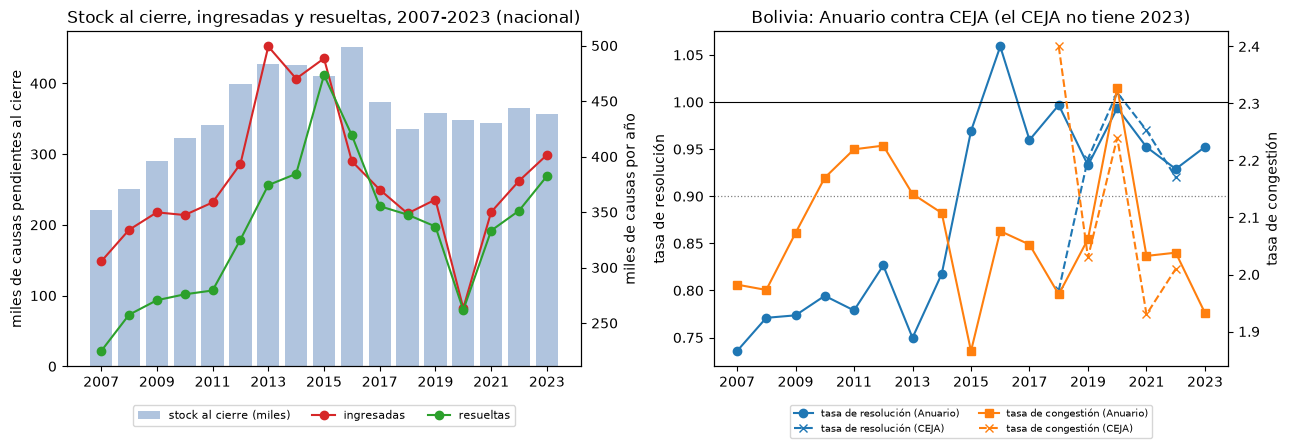

In [7]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.6))
anios = list(nac_i.index)
ejes[0].bar(anios, nac_i["pendientes_fin"] / 1000, color="lightsteelblue", label="stock al cierre (miles)")
ejes[0].set_ylabel("miles de causas pendientes al cierre")
ax2 = ejes[0].twinx()
ax2.plot(anios, nac_i["ingresadas"] / 1000, color="tab:red", marker="o", label="ingresadas")
ax2.plot(anios, nac_i["resueltas"] / 1000, color="tab:green", marker="o", label="resueltas")
ax2.set_ylabel("miles de causas por año")
ejes[0].set_title("Stock al cierre, ingresadas y resueltas, 2007-2023 (nacional)")
ejes[0].set_xticks(anios[::2])
h1, l1 = ejes[0].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ejes[0].legend(h1 + h2, l1 + l2, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, fontsize=8)
ejes[1].plot(anios, nac_i["tasa_resolucion"], color="tab:blue", marker="o", label="tasa de resolución (Anuario)")
ejes[1].plot(list(CEJA_TR), list(CEJA_TR.values()), color="tab:blue", linestyle="--", marker="x", label="tasa de resolución (CEJA)")
ejes[1].axhline(1.0, color="black", linewidth=0.8)
ejes[1].axhline(0.9, color="gray", linestyle=":", linewidth=0.9)
ejes[1].set_ylabel("tasa de resolución")
ax3 = ejes[1].twinx()
ax3.plot(anios, nac_i["tasa_congestion"], color="tab:orange", marker="s", label="tasa de congestión (Anuario)")
ax3.plot(list(CEJA_TC), list(CEJA_TC.values()), color="tab:orange", linestyle="--", marker="x", label="tasa de congestión (CEJA)")
ax3.set_ylabel("tasa de congestión")
ejes[1].set_title("Bolivia: Anuario contra CEJA (el CEJA no tiene 2023)")
ejes[1].set_xticks(anios[::2])
h1, l1 = ejes[1].get_legend_handles_labels(); h2, l2 = ax3.get_legend_handles_labels()
ejes[1].legend(h1 + h2, l1 + l2, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, fontsize=7)
plt.tight_layout()
plt.show()

## El shock de 2020 y capitales contra provincias

2019 → 2020 (nacional): ingresadas -27 %, resueltas -22 %
2020 → 2021: ingresadas +33 %, resueltas +27 %
2019 → 2023: ingresadas +11 %, resueltas +13 %
capital    stock al cierre 2007 → 2023: 182.913 → 249.091 (×1.4); tasa de resolución 2023: 0.97
provincia  stock al cierre 2007 → 2023: 37.828 → 107.417 (×2.8); tasa de resolución 2023: 0.90
pico del stock al cierre: 2016 451.090 | 2023: 356.508


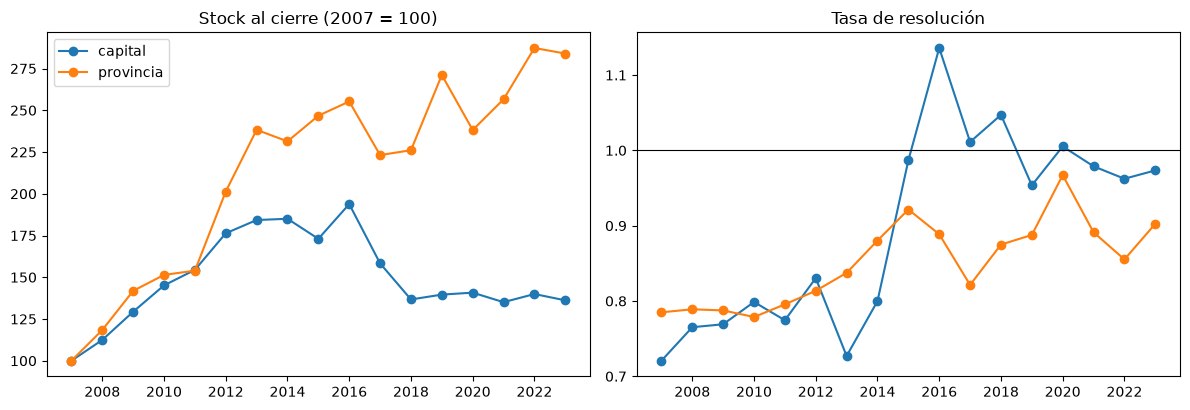

In [8]:
def cambio(anio_a, anio_b, columna, ambito="nacional"):
    t = ind[ind["ambito"] == ambito].set_index("gestion")
    return (t.loc[anio_b, columna] / t.loc[anio_a, columna] - 1) * 100
print("2019 → 2020 (nacional): ingresadas {:+.0f} %, resueltas {:+.0f} %".format(cambio(2019, 2020, "ingresadas"), cambio(2019, 2020, "resueltas")))
print("2020 → 2021: ingresadas {:+.0f} %, resueltas {:+.0f} %".format(cambio(2020, 2021, "ingresadas"), cambio(2020, 2021, "resueltas")))
print("2019 → 2023: ingresadas {:+.0f} %, resueltas {:+.0f} %".format(cambio(2019, 2023, "ingresadas"), cambio(2019, 2023, "resueltas")))
for ambito in ["capital", "provincia"]:
    t = ind[ind["ambito"] == ambito].set_index("gestion")
    print("{:<10} stock al cierre 2007 → 2023: {} → {} (×{:.1f}); tasa de resolución 2023: {:.2f}".format(
        ambito, miles(t.loc[2007, "pendientes_fin"]), miles(t.loc[2023, "pendientes_fin"]),
        t.loc[2023, "pendientes_fin"] / t.loc[2007, "pendientes_fin"], t.loc[2023, "tasa_resolucion"]))
pico = nac_i["pendientes_fin"].idxmax()
print("pico del stock al cierre:", pico, miles(nac_i.loc[pico, "pendientes_fin"]), "| 2023:", miles(nac_i.loc[2023, "pendientes_fin"]))
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2))
for ambito, color in [("capital", "tab:blue"), ("provincia", "tab:orange")]:
    t = ind[ind["ambito"] == ambito].set_index("gestion")
    ejes[0].plot(t.index, t["pendientes_fin"] / t.loc[2007, "pendientes_fin"] * 100, color=color, marker="o", label=ambito)
    ejes[1].plot(t.index, t["tasa_resolucion"], color=color, marker="o", label=ambito)
ejes[0].set_title("Stock al cierre (2007 = 100)")
ejes[0].legend()
ejes[1].axhline(1.0, color="black", linewidth=0.8)
ejes[1].set_title("Tasa de resolución")
plt.tight_layout()
plt.show()

## Resueltas por materia desde 2020
Los cuadros 9.1.2 (capitales), 9.1.6 (provincias) y 9.1.10 (nacional) dan las causas **resueltas** por materia y año. Hay tres reservas, todas
medidas aquí en lugar de ignoradas:
- **Rótulos invertidos.** Anticorrupción y violencia contra la mujer intercambian rótulos entre cuadros y entre años. Se usan los pares sumados.
- **2019.** El cuadro 9.1.10 no coincide con 9.1.2 + 9.1.6 en 2019 (civil: 43.652 contra 78.323), mientras 2020 a 2023 sí cierran. Esa
  columna se registra y **no se usa**.
- **Sin ingresadas.** Estos cuadros no traen ingresos ni stock: sirven para ver cuánto se resolvió, no cuánto quedó.

In [9]:
g = gestion[gestion["tipo_fila_derivado"] == "dato"].copy()
g = asignar_grupo(g, GRUPOS_MATERIA_SERIE)
nacional = g[g["cuadro_origen"] == "9.1.10"].pivot_table(index=["grupo_materia", "tipo_materia"], columns="gestion", values="resueltas", aggfunc="sum")
cap_pro = g[g["cuadro_origen"].isin(["9.1.2", "9.1.6"])].pivot_table(index=["grupo_materia", "tipo_materia"], columns="gestion", values="resueltas", aggfunc="sum")
dif = cap_pro.sub(nacional, fill_value=0)
# Control: 2020-2023 cierran (diferencias de unas pocas causas); 2019 no.
tolerancia = 100
assert dif[[2020, 2021, 2022, 2023]].abs().max().max() <= tolerancia, "9.1.2 + 9.1.6 no reproduce 9.1.10 en 2020-2023"
print("2020-2023: 9.1.2 + 9.1.6 reproduce 9.1.10 con una diferencia máxima de", int(dif[[2020, 2021, 2022, 2023]].abs().max().max()), "causas")
d19 = dif[2019].dropna()
print("2019: diferencia máxima de {} causas (9.1.10 no se usa para 2019)".format(miles(d19.abs().max())))
dif_2019 = pd.DataFrame({"grupo_materia": [i[0] for i in dif.index], "tipo_materia": [i[1] for i in dif.index],
                         "resueltas_2019_9_1_2_mas_9_1_6": cap_pro[2019].reindex(dif.index).values,
                         "resueltas_2019_9_1_10": nacional[2019].reindex(dif.index).values,
                         "diferencia": dif[2019].values})
dif_2019.to_csv(OUT_EDA / "serie_materia_2019_inconsistente.csv", index=False, encoding="utf-8")

res = nacional[[2020, 2021, 2022, 2023]].copy()
res["cambio_2021_2023_pct"] = (res[2023] / res[2021] - 1) * 100
res["cambio_2020_2023_pct"] = (res[2023] / res[2020] - 1) * 100
res = res.reset_index().sort_values(["tipo_materia", "cambio_2021_2023_pct"], ascending=[True, False])
res.columns = [str(c) for c in res.columns]
res.to_csv(OUT_EDA / "serie_resueltas_materia_2020_2023.csv", index=False, encoding="utf-8")
res.round(0)

2020-2023: 9.1.2 + 9.1.6 reproduce 9.1.10 con una diferencia máxima de 9 causas
2019: diferencia máxima de 34.671 causas (9.1.10 no se usa para 2019)


,grupo_materia,tipo_materia,2020,2021,2022,2023,cambio_2021_2023_pct,cambio_2020_2023_pct
2,Ejecución penal,ejecución penal,7348,7850,8852,9068,16.0,23.0
9,Trabajo y Seguridad Social,no penal,14716,16831,17995,23441,39.0,59.0
6,Niñez y Adolescencia,no penal,7178,8942,9110,11712,31.0,63.0
0,Civil y Comercial,no penal,54092,73869,85221,94769,28.0,75.0
1,Coactivo Fiscal y Tributario,no penal,2114,2110,2518,2671,27.0,26.0
3,Familia,no penal,53219,75566,79161,79210,5.0,49.0
8,Sentencia: anticorrupción + violencia,penal,1432,2508,9306,6031,140.0,321.0
10,Tribunal de sentencia: anticorrupción + violencia,penal,782,1159,1776,1964,69.0,151.0
7,Sentencia penal,penal,8141,11694,12350,16457,41.0,102.0
5,Instrucción: anticorrupción + violencia,penal,38269,46819,48382,48955,5.0,28.0


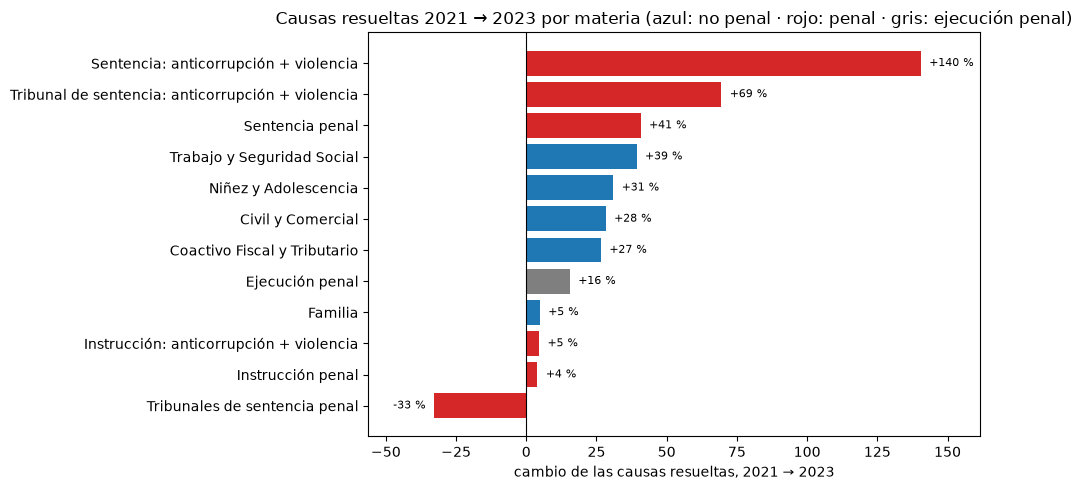

In [10]:
colores = {NO_PENAL: "tab:blue", PENAL: "tab:red", EJECUCION: "tab:gray"}
t = res.sort_values("cambio_2021_2023_pct")
fig, ax = plt.subplots(figsize=(10, 5))
barras = ax.barh(t["grupo_materia"], t["cambio_2021_2023_pct"], color=[colores[x] for x in t["tipo_materia"]])
for b, v in zip(barras, t["cambio_2021_2023_pct"]):
    ax.text(v + (3 if v >= 0 else -3), b.get_y() + b.get_height() / 2, "{:+.0f} %".format(v), va="center", ha="left" if v >= 0 else "right", fontsize=8)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("cambio de las causas resueltas, 2021 → 2023")
ax.set_title("Causas resueltas 2021 → 2023 por materia (azul: no penal · rojo: penal · gris: ejecución penal)")
ax.set_xlim(t["cambio_2021_2023_pct"].min() * 1.4 - 10, t["cambio_2021_2023_pct"].max() * 1.15)
plt.tight_layout()
plt.show()